# Lesson 9 - CWRU Window Feature Analysis

## Objective

Compare time-domain vibration features across Normal, Inner Race, Ball and Outer Race bearing conditions using non-overlapping signal windows with the same duration.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.io import loadmat
from scipy.stats import kurtosis

In [4]:
# Define the data path
cwd = Path.cwd()

if (cwd / "data").exists():
    project_root = cwd
elif (cwd.parent / "data").exists():
    project_root = cwd.parent
else:
    raise FileNotFoundError("Could not find project data folder")

data_dir = (project_root / "data" / "cwru" / "raw")

print(data_dir)
list(data_dir.iterdir())

c:\Users\User\Documents\Projects\predictive-maintenance-system\data\cwru\raw


[WindowsPath('c:/Users/User/Documents/Projects/predictive-maintenance-system/data/cwru/raw/109.mat'),
 WindowsPath('c:/Users/User/Documents/Projects/predictive-maintenance-system/data/cwru/raw/122.mat'),
 WindowsPath('c:/Users/User/Documents/Projects/predictive-maintenance-system/data/cwru/raw/135.mat'),
 WindowsPath('c:/Users/User/Documents/Projects/predictive-maintenance-system/data/cwru/raw/97.mat')]

In [5]:
# File Loader
def load_cwru_file(file_path, channel="DE_time"):
    data = loadmat(file_path)

    keys = [
        key
        for key in data.keys()
        if not key.startswith("__")
    ]

    signal_key = next(
        key
        for key in keys
        if channel in key
    )

    rpm_key = next(
        (
            key
            for key in keys
            if "RPM" in key
        ),
        None
    )

    signal = data[signal_key].squeeze()

    rpm = None
    if rpm_key is not None:
        rpm = float(
            np.asarray(
                data[rpm_key]
            ).squeeze()
        )

    return signal, rpm

In [6]:
# Load all four conditions
files = {
    "Normal": "97.mat",
    "Inner race": "109.mat",
    "Ball": "122.mat",
    "Outer race": "135.mat"
}

signals = {}
rpms = {}

for condition, filename in files.items():
    signal, rpm = load_cwru_file(data_dir / filename)
    signals[condition] = signal
    rpms[condition] = rpm

rpms

{'Normal': 1796.0, 'Inner race': 1796.0, 'Ball': 1796.0, 'Outer race': 1796.0}

## Method

- Drive-end vibration channel
- Sampling rate: 48 kHz
- Window duration: 1 second
- Non-overlapping windows
- Features: RMS, peak, peak-to-peak, standard deviation, crest factor and kurtosis

In [8]:
# Inspect recording lengths
sampling_rate = 48000

for condition, signal in signals.items():
    duration = len(signal) / sampling_rate

    print(
        f"{condition:12}"
        f"samples = {len(signal):8d} "
        f"duration = {duration:.2f} s "
        f"RPM = {rpms[condition]}"
    )

Normal      samples =   243938 duration = 5.08 s RPM = 1796.0
Inner race  samples =   243938 duration = 5.08 s RPM = 1796.0
Ball        samples =   244739 duration = 5.10 s RPM = 1796.0
Outer race  samples =   243538 duration = 5.07 s RPM = 1796.0


In [9]:
# Create segmentation function (1 second)
def segment_signal(signal, sampling_rate, window_duration=1.0):
    samples_per_window = int(sampling_rate * window_duration)
    # Calculate only how many complete windows
    number_of_windows = len(signal) // samples_per_window

    windows = []

    # For each window
    for i in range(number_of_windows):
        start = i * samples_per_window
        end = start + samples_per_window
        window = signal[start:end]
        windows.append(window)

    return windows

In [13]:
# Check how many windows each recording gives
segmented_signals = {}

for condition, signal in signals.items():
    windows = segment_signal(signal, sampling_rate, window_duration=1.0)
    segmented_signals[condition] = windows

    print(condition, len(windows))

Normal 5
Inner race 5
Ball 5
Outer race 5


In [14]:
# Feature extraction
def extract_features(signal):
    # Calculate time-domain features
    mean_value = np.mean(signal)
    rms = np.sqrt(np.mean(signal ** 2))
    peak = np.max(np.abs(signal))
    peak_to_peak = np.ptp(signal)
    standard_deviation = np.std(signal)

    # Calculate impulsive features
    crest_factor = peak / rms
    kurtosis_value = kurtosis(signal, fisher=False, bias=False)

    return {
        "mean": mean_value,
        "rms": rms,
        "peak": peak,
        "peak_to_peak": peak_to_peak,
        "std": standard_deviation,
        "crest_factor": crest_factor,
        "kurtosis": kurtosis_value,
    }

In [15]:
# Extract features from every window
feature_rows = []

for condition, windows in segmented_signals.items():
    # Default index starts at 1 instead of 0
    for window_number, window in enumerate(windows, start=1):
        features = extract_features(window)
        features["condition"] = condition
        features["window"] = window_number
        features["rpm"] = rpms[condition]
        
        feature_rows.append(features)

In [17]:
# Create DataFrame
feature_df = pd.DataFrame(feature_rows)

feature_df.head()

,mean,rms,peak,peak_to_peak,std,crest_factor,kurtosis,condition,window,rpm
0,0.011776,0.073485,0.286638,0.540314,0.072535,3.900647,2.792965,Normal,1,1796.0
1,0.012638,0.072867,0.311254,0.575778,0.071762,4.271556,2.777341,Normal,2,1796.0
2,0.013074,0.073034,0.264107,0.514863,0.071854,3.616238,2.705905,Normal,3,1796.0
3,0.011949,0.074928,0.273286,0.538645,0.073969,3.647339,2.796947,Normal,4,1796.0
4,0.013471,0.074417,0.260561,0.503598,0.073188,3.501345,2.754723,Normal,5,1796.0


In [20]:
# Check how many windows belong to each condition
feature_df.groupby("condition").size()

len(feature_df)

20

In [22]:
# Calculate summary
summary = (
    feature_df.groupby("condition")
    [
        [
            "rms",
            "peak",
            "peak_to_peak",
            "std",
            "crest_factor",
            "kurtosis"
        ]
    ].agg(
        ["mean", "std", "median"]
    )
)

summary

rms                          peak                      \
                mean       std    median      mean       std    median   
condition                                                                
Ball        0.149417  0.002194  0.148724  0.664106  0.060474  0.679252   
Inner race  0.588018  0.001851  0.588211  3.362538  0.136003  3.291508   
Normal      0.073746  0.000894  0.073485  0.279169  0.020573  0.273286   
Outer race  1.257505  0.036417  1.257293  6.174363  0.285990  6.175281   

           peak_to_peak                            std                      \
                   mean       std     median      mean       std    median   
condition                                                                    
Ball           1.225866  0.076386   1.198287  0.145855  0.002185  0.145158   
Inner race     6.161342  0.159099   6.073452  0.582961  0.001482  0.583653   
Normal         0.534640  0.027818   0.538645  0.072662  0.000930  0.072535   
Outer race    12.097826  0.466327  12.055091  1.257439  0.036422  1.257248   

           crest_factor                      kurtosis                      
                   mean       std    median      mean       std    median  
condition                                                                  
Ball           4.443641  0.387963  4.434151  3.129922  0.052628  3.111644  
Inner race     5.718541  0.233969  5.580052  6.032188  0.041367  6.028526  
Normal         3.787425  0.307397  3.647339  2.765576  0.037253  2.777341  
Outer race     4.908620  0.120447  4.893906  6.722909  0.124792  6.749606

### RMS observations

- The Normal condition showed the lowest median RMS.
- The Outer Race condition showed the highest median RMS.

### Crest factor observations

- The Normal condition has the lowest median crest factor.
- The inner race conditon has the highest median crest factor.

### Kurtosis observations

- The Normal condition has the lowest median kurtosis.
- The outer race condition has the highest median kurtosis.
- The inner race condition has the second-highest median kurtosis, and the distance between it and outer race is not as big compared to distance between it and normal condition.

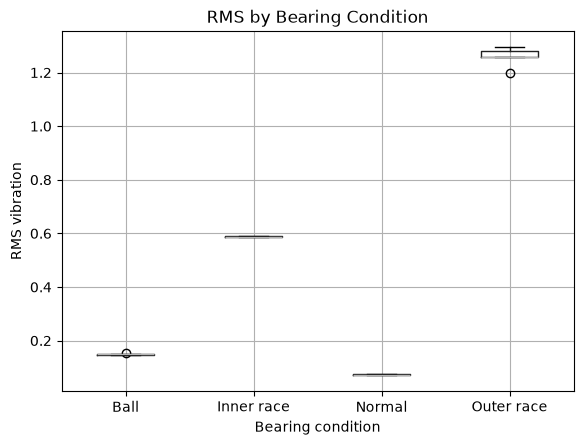

In [24]:
# RMS Box Plot
feature_df.boxplot(column="rms", by="condition")

plt.ylabel("RMS vibration")
plt.xlabel("Bearing condition")
plt.title("RMS by Bearing Condition")

plt.suptitle("")
plt.show()

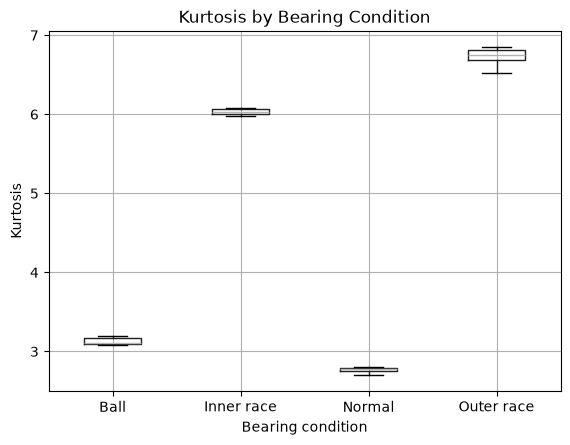

In [26]:
# Kurtosis Box Plot
feature_df.boxplot(column="kurtosis", by="condition")

plt.ylabel("Kurtosis")
plt.xlabel("Bearing condition")
plt.title("Kurtosis by Bearing Condition")

plt.suptitle("")
plt.show()

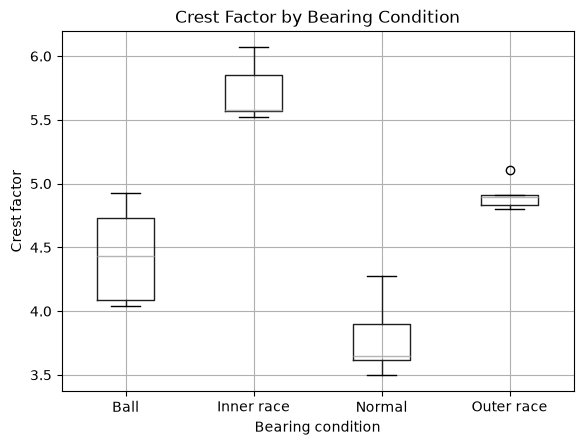

In [28]:
# Crest Factor Box Plot
feature_df.boxplot(column="crest_factor", by="condition")

plt.ylabel("Crest factor")
plt.xlabel("Bearing condition")
plt.title("Crest Factor by Bearing Condition")

plt.suptitle("")
plt.show()

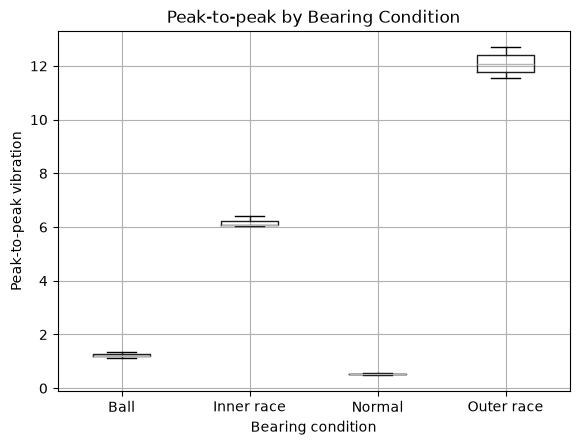

In [30]:
# Peak-to-peak Box Plot
feature_df.boxplot(column="peak_to_peak", by="condition")

plt.ylabel("Peak-to-peak vibration")
plt.xlabel("Bearing condition")
plt.title("Peak-to-peak by Bearing Condition")

plt.suptitle("")
plt.show()

In [32]:
# Calculate the healthy median
healthy_median = (
    feature_df[
        feature_df["condition"] == "Normal"
    ]
    [
        [
            "rms",
            "peak",
            "peak_to_peak",
            "crest_factor",
            "kurtosis"
        ]
    ].median()
)

healthy_median

rms             0.073485
peak            0.273286
peak_to_peak    0.538645
crest_factor    3.647339
kurtosis        2.777341
dtype: float64

In [33]:
# Calculate median for every condition
condition_median = (
    feature_df.groupby("condition")
    [
        [
            "rms",
            "peak",
            "peak_to_peak",
            "crest_factor",
            "kurtosis"
        ]
    ].median()
)

In [35]:
# Normalize
relative_to_healthy = condition_median / healthy_median

relative_to_healthy

,rms,peak,peak_to_peak,crest_factor,kurtosis
condition,,,,,
Ball,2.023881,2.485496,2.224632,1.215722,1.120368
Inner race,8.004543,12.044181,11.275428,1.529897,2.170611
Normal,1.000000,1.000000,1.000000,1.000000,1.000000
Outer race,17.109603,22.596393,22.380403,1.341774,2.430241


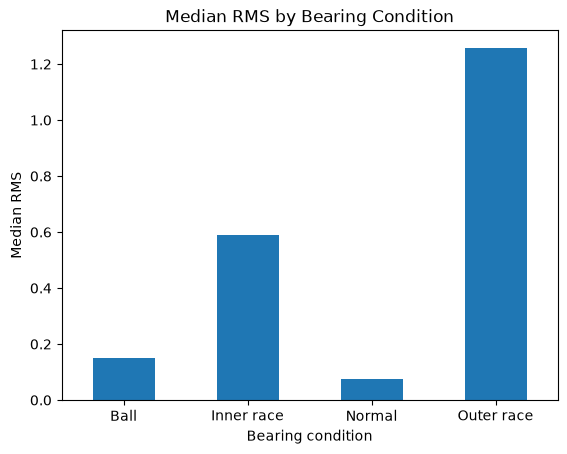

In [37]:
# RMS median comparison plot
rms_medians = feature_df.groupby("condition")["rms"].median()

# Plot bar chart
rms_medians.plot(kind="bar")
plt.ylabel("Median RMS")
plt.xlabel("Bearing condition")
plt.title("Median RMS by Bearing Condition")

# Make x-axis label horizontal
plt.xticks(rotation=0)
plt.show()

In [ ]:
# Calculate coefficient of variation (CV)
# Lower means little variation, higher means larger fluctuations relative to mean level
# Calculate the mean and standard deviation first
rms_stats = feature_df.groupby("condition")["rms"].agg(["mean", "std"])

rms_stats

,mean,std
condition,,
Ball,0.149417,0.002194
Inner race,0.588018,0.001851
Normal,0.073746,0.000894
Outer race,1.257505,0.036417


In [41]:
# Calculate coefficient of variaton (CV) and add it in
rms_stats["cv"] = rms_stats["std"] / rms_stats["mean"]

rms_stats

,mean,std,cv
condition,,,
Ball,0.149417,0.002194,0.014682
Inner race,0.588018,0.001851,0.003147
Normal,0.073746,0.000894,0.012120
Outer race,1.257505,0.036417,0.028960


In [42]:
# Save dataset
output_path = project_root / "results" / "cwru_window_features.csv"

feature_df.to_csv(output_path, index=False)
print(output_path)

c:\Users\User\Documents\Projects\predictive-maintenance-system\results\cwru_window_features.csv


In [44]:
# Create a healthy threshold
# Extract healthy windows
healthy_rms = feature_df[feature_df["condition"] == "Normal"]["rms"]

# Calculate
healthy_rms_mean = healthy_rms.mean()
healthy_rms_std = healthy_rms.std()
rms_threshold = healthy_rms_mean + 3 * healthy_rms_std

print("Healthy RMS mean:", healthy_rms_mean)
print("Healthy RMS std:", healthy_rms_std)
print("Provisional threshold:", rms_threshold)

Healthy RMS mean: 0.07374595582117749
Healthy RMS std: 0.000893814732097519
Provisional threshold: 0.07642740001747005


In [46]:
feature_df["rms_abnormal"] = feature_df["rms"] > rms_threshold

# Count how many windows exceed the healthy RMS threshold
pd.crosstab(feature_df["condition"], feature_df["rms_abnormal"])

rms_abnormal,False,True
condition,,
Ball,0,5
Inner race,0,5
Normal,5,0
Outer race,0,5


In [48]:
# Create healthy threshold for kurtosis
healthy_kurtosis = feature_df[feature_df["condition"] == "Normal"]["kurtosis"]

# Calculate
kurtosis_threshold = healthy_kurtosis.mean() + 3 * healthy_kurtosis.std()
feature_df["kurtosis_abnormal"] = feature_df["kurtosis"] > kurtosis_threshold

pd.crosstab(feature_df["condition"], feature_df["kurtosis_abnormal"])

kurtosis_abnormal,False,True
condition,,
Ball,0,5
Inner race,0,5
Normal,5,0
Outer race,0,5


In [49]:
# Combine two indicators (| is or on Pandas)
feature_df["any_abnormal"] = (
    feature_df["rms_abnormal"] | feature_df["kurtosis_abnormal"]
)

pd.crosstab(feature_df["condition"], feature_df["any_abnormal"])

any_abnormal,False,True
condition,,
Ball,0,5
Inner race,0,5
Normal,5,0
Outer race,0,5


## Preliminary Findings

The RMS and kurtosis values for Inner race, Outer race and Ball conditions were flagged as abnormal for all windows.